# MIMIC-IV sepsis: WIS results so far

Val split, 5 seeds, CQL alpha 0.0325, gamma 0.975, 1007 stays (948 last at least 24 h, 799 at least 48 h).

## Setup
- **Nulls:** the mean discounted return of the logged data is −0.381 for the trajectory estimator. The stepwise estimator's own null is −0.275. A policy equal to the clinician should give these.
- **Cap p:** clips each stay's weight at the p-th percentile of the log-weights. Low p is close to unweighted. High p is close to uncapped.

## The behaviour model is adequate
- BC beats a no-state baseline by about 0.45 nats/hour (fluid) and 0.36 (vaso).
- AUROC is 0.96 to 0.97 for both gates.
- The vaso gate is calibrated. The fluid gate under-predicts firing (0.65 predicted vs 0.72 observed).
- The seeds agree with each other (Spearman 0.80 to 0.85).

BC is not the source of the WIS problem.

## Two defects in the WIS pipeline, found and fixed
1. **Gate smoothing.** The BC density used a label-smoothed gate and the target density a plain one. That inflated every log-ratio by about +0.12 per hour, growing with stay length.
2. **Asymmetric z-clip.** The target clipped the magnitude z-score at 10 and the behaviour did not. Fired doses far in BC's low tail (z of −10 to −27) gave single-row log-ratios of +20 to +100. One row decided a stay's whole weight, which corrupted every cap from 99 downward.

The behaviour is now scored with the same function and clipping as the target. After the fix, the BC-vs-itself control gives a mean log-ratio of +0.000 per hour. Both estimators sit exactly at their nulls at every cap in all five seeds (ESS 100%).

## Cross-seed BC control (a clinician-like policy)
Target is BC seed j, behaviour is BC seed i. Mean log-ratio −0.02 to +0.03 per hour.

| Estimator | Caps up to 50 (ESS 54–99%) | Caps 75 and above |
|---|---|---|
| Stepwise | within about ±0.25 of its null per seed | collapses: −0.1 to −5.0 (ESS 36% and below) |
| Trajectory | +0.2 to +0.5 at cap 25, then −0.5 to −0.1 at cap 50 | −1.5 to −9.5 |

The trajectory estimator is biased even for a clinician-like policy. The stepwise estimator is usable up to cap 50.

## CQL alpha 0.0325
| Cap | Trajectory | Stepwise (null −0.275) |
|---|---|---|
| 10 | +0.10 to +0.19 | −0.35 to −0.16 |
| 25 | +0.46 to +0.83 | −0.23 to +0.16 |
| 50 | +0.81 to +1.23 | −1.01 to −0.11 |
| 90 | +1.7 to +4.6 | −1.87 to +0.19 |

The trajectory estimator is above the null at every cap from 10 up, and rises with the cap. Stepwise stays in the control's band for most seeds at caps 10 to 50.

## Why the trajectory gain is a length effect
- **Length correlation:** the rank correlation between a stay's total log-ratio and its length is −0.59 in every CQL seed and −0.11 to +0.08 in the control. The CQL per-hour log-ratio is negative, so long stays get tiny weights. The top weights go to short stays, which have the best returns.
- **Fixed horizon** (first 24 or 48 hours of every stay, so exposure is equal): the gain disappears. The 48-hour differences from the null at caps 25 and 50 are negative in all five seeds (means −0.24 and −0.52), against about −0.02 for the control. At caps 75 and 90 the CQL values are within the control's noise (±0.5).

## About the ESS
ESS ≈ 100 − p in every run, controls included. That is what the cap does when the weights span many orders of magnitude: the estimate is the mean of the top (100 − p)% of stays. It reflects weight compounding over long stays, not a CQL-specific failure, and it is not evidence that the policy is bad.

## What we can and cannot conclude
- WIS shows **no detectable improvement** over the clinician at alpha 0.0325. Stepwise is at or slightly above its null at caps 10 to 25 and mixed at cap 50 (seed 4 is the one clear negative, −1.01). The only consistent hint of a deficit is the fixed-horizon comparison at 48 hours (all five seeds negative at caps 25 and 50, means −0.24 and −0.52). That is about the size of the control's per-seed noise, so it is suggestive and not established.
- The earlier large SARSA advantage at alpha 0.01 is not confirmed. The policy puts low probability on the clinician's actions, so there is little overlap and WIS has low power. This is "not detectable", not "no benefit".

## Not yet done
Alpha 0.01 under the final pipeline (earlier numbers predate both fixes), the test split, CHOC, the per-drug log-ratio decomposition, and the doubly robust estimate.

In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_wis as wis
import src.rl.evaluate_cql_alpha_sweep as ev
from src.rl.evaluate_fqe_final_seeds import _by_seed

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])

[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

In [2]:
ALPHA = 0.0325
rl_root = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv"

cql_dir = os.path.join(rl_root, "cql_with_logprobs", "split_0", "sepsis", "combined_hourly_iv-vasoactive_inotropic_score",
                       "with_actions", "health_score_change_only", "alpha_sweep")
bc_dir = os.path.join(rl_root, "bc_with_logprobs", "split_0", "sepsis", "combined_hourly_iv-vasoactive_inotropic_score", 
                      "with_actions", "five_seeds")

for name, d in (("cql_dir", cql_dir), ("bc_dir", bc_dir)):
    print(f"{name}: {d}")

is_alpha = lambda r: np.isclose(float(r.get("cql_alpha")), ALPHA)
cql_study = R.make_study(cql_dir, family="cql", group_by=(), include=is_alpha, name="cql")
bc_study = R.make_study(bc_dir, family="bc", group_by=(), name="bc")

cql_models = M.load_study_models(cql_study)[()]
bc_models = M.load_study_models(bc_study)[()]
assert sorted(cql_models) == sorted(bc_models) == [0, 1, 2, 3, 4]

# every CQL seed must be paired with the BC seed that shares its state embedding
for s in sorted(cql_models):
    print(s, cql_models[s].record.data_identity.short(), "|", bc_models[s].record.data_identity.short())

store = D.DataStore(keep=("val", "test"))

cql_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep
bc_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/bc_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/five_seeds
  loaded LoadedModel(cql seed 0: actor, critic)
  loaded LoadedModel(cql seed 1: actor, critic)
  loaded LoadedModel(cql seed 2: actor, critic)
  loaded LoadedModel(cql seed 3: actor, critic)
  loaded LoadedModel(cql seed 4: actor, critic)
  loaded LoadedModel(bc seed 0: actor)
  loaded LoadedModel(bc seed 1: actor)
  loaded LoadedModel(bc seed 2: actor)
  loaded LoadedModel(bc seed 3: actor)
  loaded LoadedModel(bc seed 4: actor)
0 state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7] | state seed 0, shared reward [mimic_iv_dynamic

In [3]:
wis_cache = os.path.join(rl_root, "wis_cache")   # or any folder you like

# BC control

  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, val)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:1634: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_control_self_val_sweep.pkl was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:2166: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_control_self_val_seed0.npz was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


seed 0 (target BC 0): mean log-ratio per hour +0.000
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=-0.381 (traj ESS 100.0%)  step=-0.275 (step ESS 100.0%)  [nulls -0.381 / -0.275]
  wcap=  5.0  traj=-0.381 (traj ESS 100.0%)  step=-0.275 (step ESS 100.0%)  [nulls -0.381 / -0.275]
  wcap= 10.0  traj=-0.381 (traj ESS 100.0%)  step=-0.275 (step ESS 100.0%)  [nulls -0.381 / -0.275]
  wcap= 25.0  traj=-0.381 (traj ESS 100.0%)  step=-0.275 (step ESS 100.0%)  [nulls -0.381 / -0.275]
  wcap= 50.0  traj=-0.381 (traj ESS 100.0%)  step=-0.275 (step ESS 100.0%)  [nulls -0.381 / -0.275]
  wcap= 75.0  traj=-0.381 (traj ESS 100.0%)  step=-0.275 (step ESS 100.0%)  [nulls -0.381 / -0.275]
  wcap= 90.0  traj=-0.381 (traj ESS 100.0%)  step=-0.275 (step ESS 100.0%)  [nulls -0.381 / -0.275]
  wcap= 95.0  traj=-0.381 (traj ESS 100.0%)  step=-0.275 (step ESS 100.0%)  [nu

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:2166: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_control_self_val_seed1.npz was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


... (13 outputs left out)

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:2166: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_control_cross_val_seed3.npz was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


seed 3 (target BC 4): mean log-ratio per hour +0.029
CQL seeds loaded: [3]
BC seeds loaded:  [3]
Matched 1 (CQL, BC) pairs by results.json seed: [3]

=== Seed 3: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=-0.331 (traj ESS 99.0%)  step=-0.282 (step ESS 99.2%)  [nulls -0.381 / -0.275]
  wcap=  5.0  traj=-0.078 (traj ESS 95.1%)  step=-0.266 (step ESS 95.9%)  [nulls -0.381 / -0.275]
  wcap= 10.0  traj=0.218 (traj ESS 90.5%)  step=-0.199 (step ESS 91.7%)  [nulls -0.381 / -0.275]
  wcap= 25.0  traj=0.322 (traj ESS 76.4%)  step=-0.202 (step ESS 80.1%)  [nulls -0.381 / -0.275]
  wcap= 50.0  traj=-0.238 (traj ESS 54.7%)  step=-0.137 (step ESS 63.5%)  [nulls -0.381 / -0.275]
  wcap= 75.0  traj=-2.369 (traj ESS 26.0%)  step=-0.141 (step ESS 35.5%)  [nulls -0.381 / -0.275]
  wcap= 90.0  traj=-3.550 (traj ESS 10.4%)  step=-0.706 (step ESS 16.1%)  [nulls -0.381 / -0.275]
  wcap= 95.0  traj=-4.729 (traj ESS 5.2%)  step=-1.452 (step ESS 8.8%)  [nulls -0.381 / -0.275]

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:2166: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_control_cross_val_seed4.npz was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


seed 4 (target BC 0): mean log-ratio per hour -0.020
CQL seeds loaded: [4]
BC seeds loaded:  [4]
Matched 1 (CQL, BC) pairs by results.json seed: [4]

=== Seed 4: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=-0.323 (traj ESS 99.1%)  step=-0.248 (step ESS 99.2%)  [nulls -0.381 / -0.275]
  wcap=  5.0  traj=-0.081 (traj ESS 95.0%)  step=-0.256 (step ESS 95.9%)  [nulls -0.381 / -0.275]
  wcap= 10.0  traj=0.143 (traj ESS 90.5%)  step=-0.290 (step ESS 92.0%)  [nulls -0.381 / -0.275]
  wcap= 25.0  traj=0.205 (traj ESS 76.1%)  step=-0.312 (step ESS 79.8%)  [nulls -0.381 / -0.275]
  wcap= 50.0  traj=-0.451 (traj ESS 53.7%)  step=-0.367 (step ESS 61.9%)  [nulls -0.381 / -0.275]
  wcap= 75.0  traj=-2.192 (traj ESS 26.6%)  step=-0.340 (step ESS 36.0%)  [nulls -0.381 / -0.275]
  wcap= 90.0  traj=-4.781 (traj ESS 10.8%)  step=-0.031 (step ESS 16.2%)  [nulls -0.381 / -0.275]
  wcap= 95.0  traj=-3.874 (traj ESS 5.1%)  step=-0.196 (step ESS 8.7%)  [nulls -0.381 / -0.275]

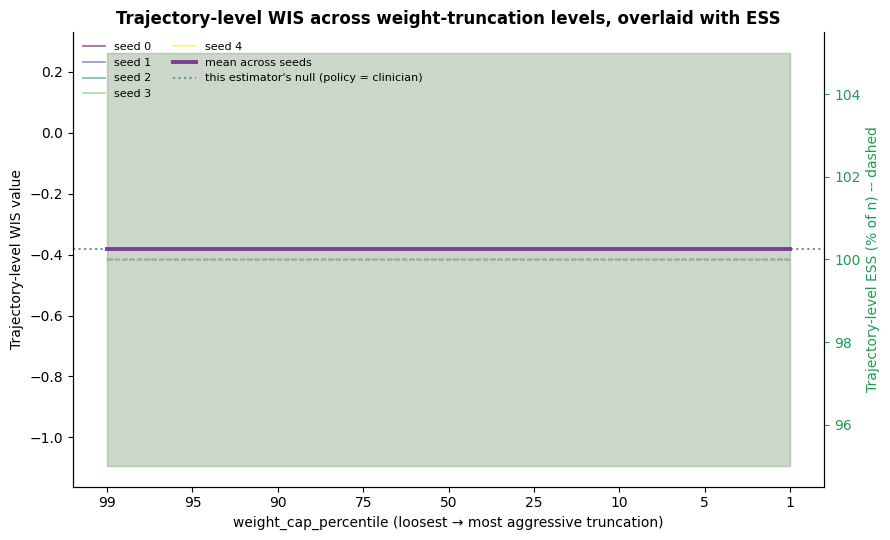

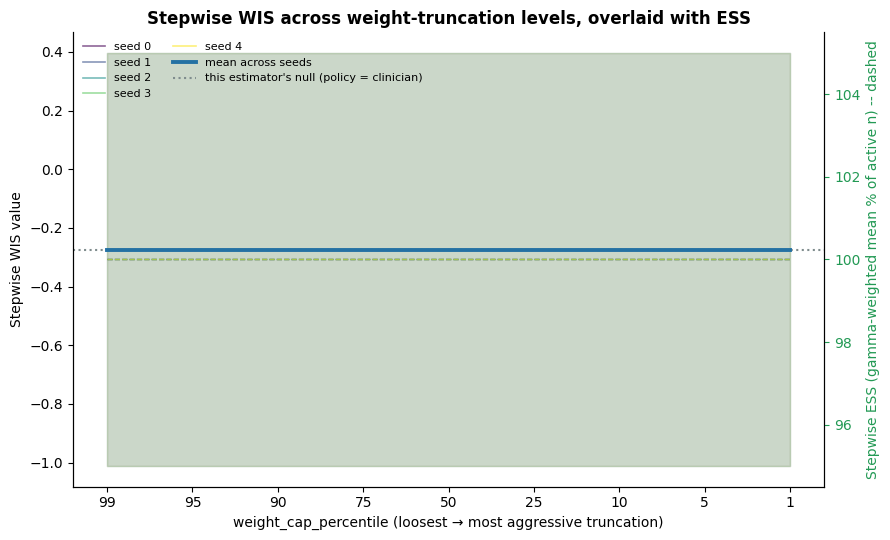

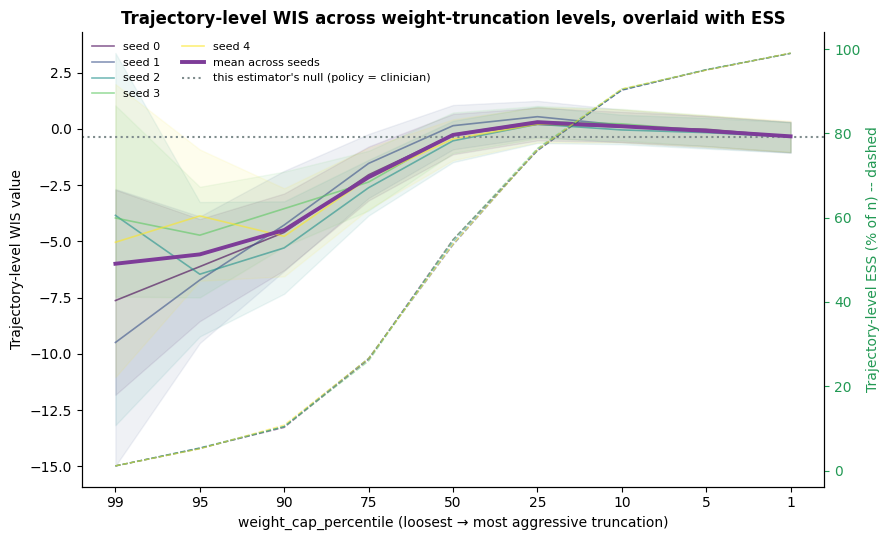

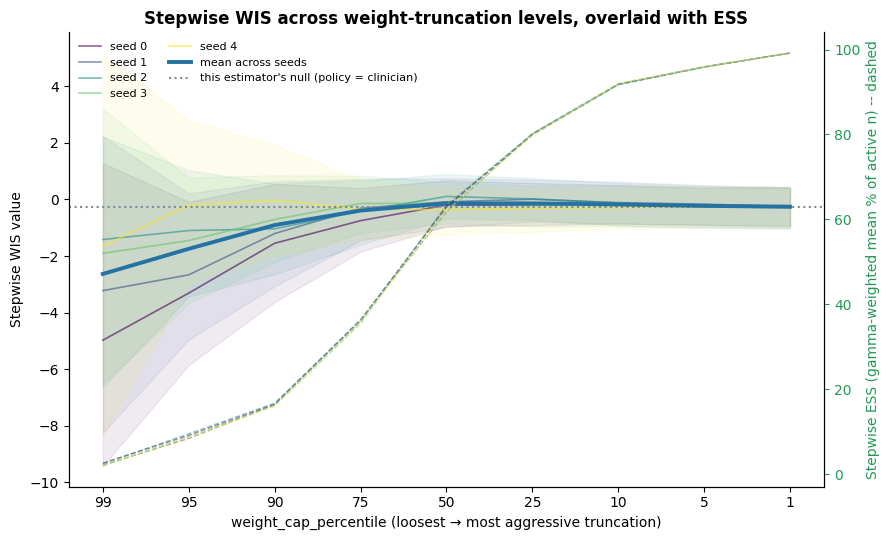

In [4]:
gamma = wis.discount_from_models(cql_models)
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]

ctrl_self  = wis.run_bc_control_sweep(bc_models, store, caps, gamma, mode="self",  split="val", cache_dir=wis_cache)
ctrl_cross = wis.run_bc_control_sweep(bc_models, store, caps, gamma, mode="cross", split="val", cache_dir=wis_cache)

for name, rows in (("self", ctrl_self), ("cross-seed", ctrl_cross)):
    print(f"\n######## control: {name}")
    wis.plot_weight_truncation_sweep(rows, estimator="trajectory")
    wis.plot_weight_truncation_sweep(rows, estimator="stepwise")

In [6]:
import src.rl.evaluate_bc_final_seeds as eval_bc
from src.rl.evaluate_fqe_final_seeds import _by_seed
import pandas as pd

seed = 0
m = _by_seed(bc_models)[seed]
p = store.processor(m, "val")
d = np.load(os.path.join(wis_cache, f"wis_control_self_val_seed{seed}.npz"))
lr = d["target_lp"] - d["behavior_lp"]
print("log-ratio percentiles (0, 0.1, 1, 50, 99, 99.9, 100):", np.percentile(lr, [0, .1, 1, 50, 99, 99.9, 100]).round(3))

rows = eval_bc.bc_rows(m, p)
worst = np.argsort(-np.abs(lr))[:12]
tab = pd.DataFrame({"row": worst, "lr": lr[worst]})
for drug in ("fluid", "vaso"):
    r = rows[drug]
    tab[f"{drug}_dose"] = r["dose"][worst]; tab[f"{drug}_p"] = r["p"][worst]
    tab[f"{drug}_mean"] = r["raw_mean"][worst]; tab[f"{drug}_z"] = r["z"][worst]
print(tab.round(4).to_string(index=False))

bounds = wis.get_trajectory_boundaries(p)
tot = np.array([lr[s:e].sum() for s, e, _ in bounds]); L = np.array([e - s for s, e, _ in bounds])
for k in np.argsort(-tot)[:5]:
    s, e, _ = bounds[k]; j = s + np.argmax(np.abs(lr[s:e]))
    print(f"stay {k}: length {L[k]}, total log-ratio {tot[k]:+.1f}, share from its single worst row {lr[j] / tot[k]:.2f}")

log-ratio percentiles (0, 0.1, 1, 50, 99, 99.9, 100): [-0.    -0.    -0.     0.     0.     0.    97.474]
   row      lr  fluid_dose  fluid_p  fluid_mean  fluid_z  vaso_dose  vaso_p  vaso_mean   vaso_z
 40272 97.4741      0.0030   0.9688     -0.3381 -17.1741     0.0000  0.0347    -1.8746  -7.2265
 70892 60.1550      0.0139   0.9864     -0.4041 -14.8428     0.0000  0.1669    -1.1053 -13.6646
151852 46.1975      0.1343   0.9859     -0.1216  -6.1098     0.0118  0.9933     0.4005 -13.8706
100130 36.4258      0.0139   0.9819      0.0035 -13.1473     0.0000  0.9903     0.3938 -24.6976
117673 26.9267      0.2434   0.9840     -0.5414  -2.2866     0.0101  0.9916    -0.3573 -12.4038
 46181 21.8079      0.0625   0.9794     -0.0784 -11.9840     0.0000  0.9922     0.3175 -27.6212
115611 16.6330      0.0015   0.9109     -1.2053 -11.5441     0.0000  0.0623    -1.6951 -11.1973
  8596 12.5850      0.0015   0.9368     -0.8826 -11.1879     0.0000  0.0195    -1.9998  -6.7653
164660  7.9285      0.2790   0.

# cql models

In [5]:
results = wis.run_wis_for_models(cql_models, bc_models, store, split="val", gamma=0.975,
                                 weight_cap_percentile=None, include_myopic=False,
                                 cache_dir=wis_cache)

  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, val)


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type

=== Seed 0 ===


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:1597: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed0.npz was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: -19.0432  [-26.2545, 13.0587]  ESS=1.1/1007 (0.1%)
  Stepwise WIS:         -12.2095  [-19.2356, 9.7621]
  Minus null (policy = clinician): trajectory -18.662 [-26.123, +13.514]   stepwise -11.935 [-18.997, +9.938]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 96.0%)
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type

=== Seed 1 ===


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:1597: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed1.npz was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: 7.8977  [-25.6477, 8.4644]  ESS=1.1/1007 (0.1%)
  Stepwise WIS:         -19.3957  [-25.8007, 0.0173]
  Minus null (policy = clinician): trajectory +8.279 [-25.076, +9.237]   stepwise -19.121 [-25.479, +0.119]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 94.1%)
  building processors for state seed 2, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type

=== Seed 2 ===


... (2 outputs left out)

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:1597: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed3.npz was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: -15.2650  [-15.2650, 13.8479]  ESS=1.0/1007 (0.1%)
  Stepwise WIS:         8.2372  [-6.2915, 13.5239]
  Minus null (policy = clinician): trajectory -14.884 [-15.422, +14.241]   stepwise +8.512 [-5.878, +14.034]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)
  building processors for state seed 4, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type

=== Seed 4 ===


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:1597: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed4.npz was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: 8.4644  [-15.3452, 13.2453]  ESS=1.0/1007 (0.1%)
  Stepwise WIS:         0.2702  [-15.8476, 13.7770]
  Minus null (policy = clinician): trajectory +8.846 [-15.468, +14.058]   stepwise +0.545 [-15.690, +14.237]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)


In [7]:
import pandas as pd

def wis_table(results):
    rows = []
    for r in results:
        t, s, ci, dg = r["trajectory_wis"], r["stepwise_wis"], r["bootstrap_ci"], r["weight_diagnostics"]
        rows.append({"seed": r["seed"], "baseline": r["baseline_mean"],
                     "traj": t["value"], "traj_lo": ci["trajectory"]["ci_lower"], "traj_hi": ci["trajectory"]["ci_upper"],
                     "step": s["value"], "step_lo": ci["stepwise"]["ci_lower"], "step_hi": ci["stepwise"]["ci_upper"],
                     "ess_frac": dg["ess_frac"]})
    return pd.DataFrame(rows).round(3)

res_by_cap = {}
for cap in (25, 50):
    print(f"\n######## weight_cap_percentile = {cap}")
    res_by_cap[cap] = wis.run_wis_for_models(cql_models, bc_models, store, split="val", gamma=0.975,
                                             weight_cap_percentile=cap, include_myopic=False,
                                             cache_dir=wis_cache)
    display(wis_table(res_by_cap[cap]))


######## weight_cap_percentile = 25

=== Seed 0 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed0.npz
  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: 0.5448  [-0.2849, 1.3154]  ESS=755.0/1007 (75.0%)
  Stepwise WIS:         -0.0262  [-0.8991, 0.6885]
  Minus null (policy = clinician): trajectory +0.926 [+0.592, +1.319]   stepwise +0.249 [-0.121, +0.589]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 1.5% of total weight (max single trajectory: 0.1%)

=== Seed 1 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed1.npz
  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: 0.8262  [-0.0353, 1.5625]  ESS=755.8/1007 (75.1%)
  Stepwise WIS:         0.1586  [-0.6595, 0.9238]
  Minus null (policy = clinician): trajecto

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,-0.381,0.545,-0.285,1.315,-0.026,-0.899,0.689,0.750
1,1,-0.381,0.826,-0.035,1.562,0.159,-0.660,0.924,0.751
2,2,-0.381,0.762,-0.097,1.486,0.053,-0.792,0.823,0.750
3,3,-0.381,0.637,-0.184,1.372,-0.158,-0.977,0.616,0.750
4,4,-0.381,0.456,-0.358,1.276,-0.234,-1.013,0.557,0.751



######## weight_cap_percentile = 50

=== Seed 0 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed0.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:1634: UserWarning: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_results_alpha0.0325_val_cap50.pkl was made with different models or settings; recomputing
  warnings.warn(f"{path} was made with different models or settings; recomputing")


  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: 0.8854  [-0.1983, 1.9182]  ESS=505.2/1007 (50.2%)
  Stepwise WIS:         -0.1056  [-1.0496, 0.8788]
  Minus null (policy = clinician): trajectory +1.267 [+0.608, +2.017]   stepwise +0.169 [-0.460, +0.902]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 2.2% of total weight (max single trajectory: 0.2%)

=== Seed 1 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed1.npz
  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: 1.2298  [0.1405, 2.1628]  ESS=505.0/1007 (50.2%)
  Stepwise WIS:         -0.4506  [-1.3668, 0.6311]
  Minus null (policy = clinician): trajectory +1.611 [+0.919, +2.222]   stepwise -0.176 [-0.816, +0.599]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 2.2% of total weight (max single trajectory: 0.2%)

=== Seed 2 ===
  

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,-0.381,0.885,-0.198,1.918,-0.106,-1.050,0.879,0.502
1,1,-0.381,1.230,0.140,2.163,-0.451,-1.367,0.631,0.502
2,2,-0.381,1.068,0.008,2.113,-0.127,-1.094,0.861,0.502
3,3,-0.381,1.121,0.116,2.176,-0.157,-1.140,0.751,0.501
4,4,-0.381,0.809,-0.239,1.766,-1.013,-1.964,-0.001,0.501


gamma = 0.975 (CQL models' saved discount)
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_val_seed0.npz
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=-0.323 (traj ESS 98.9%)  step=-0.227 (step ESS 99.1%)  [nulls -0.381 / -0.275]
  wcap=  5.0  traj=-0.124 (traj ESS 94.9%)  step=-0.289 (step ESS 95.7%)  [nulls -0.381 / -0.275]
  wcap= 10.0  traj=0.165 (traj ESS 90.0%)  step=-0.255 (step ESS 93.1%)  [nulls -0.381 / -0.275]
  wcap= 25.0  traj=0.545 (traj ESS 75.0%)  step=-0.026 (step ESS 76.4%)  [nulls -0.381 / -0.275]
  wcap= 50.0  traj=0.885 (traj ESS 50.2%)  step=-0.106 (step ESS 51.5%)  [nulls -0.381 / -0.275]
  wcap= 75.0  traj=1.747 (traj ESS 25.2%)  step=0.354 (step ESS 26.1%)  [nulls -0.381 / -0.275]
  wcap= 90.0  traj=3.413 (traj ESS 10.4%)  step=0.191 (step ESS 11.6%)  [

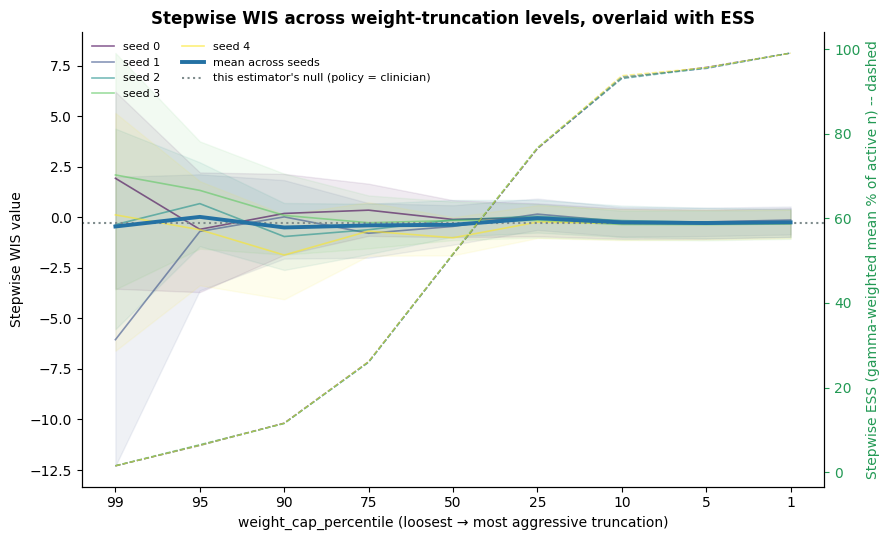

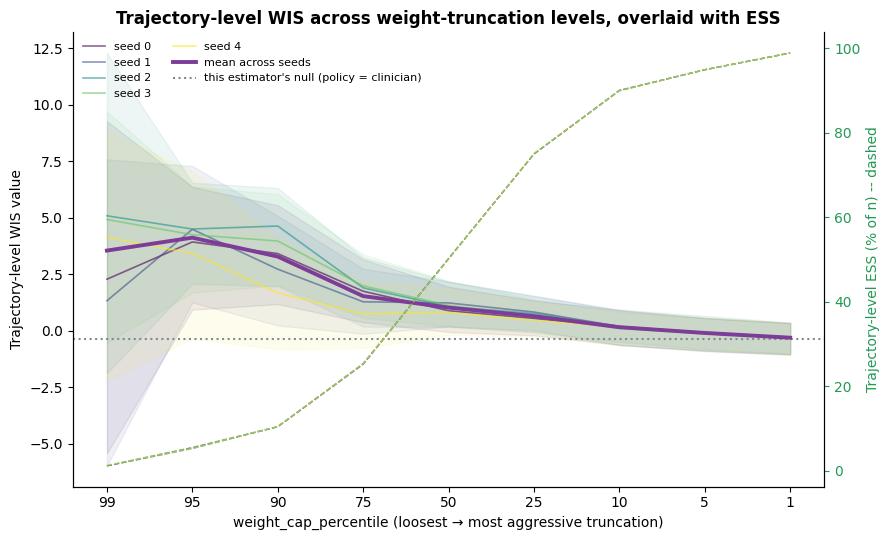

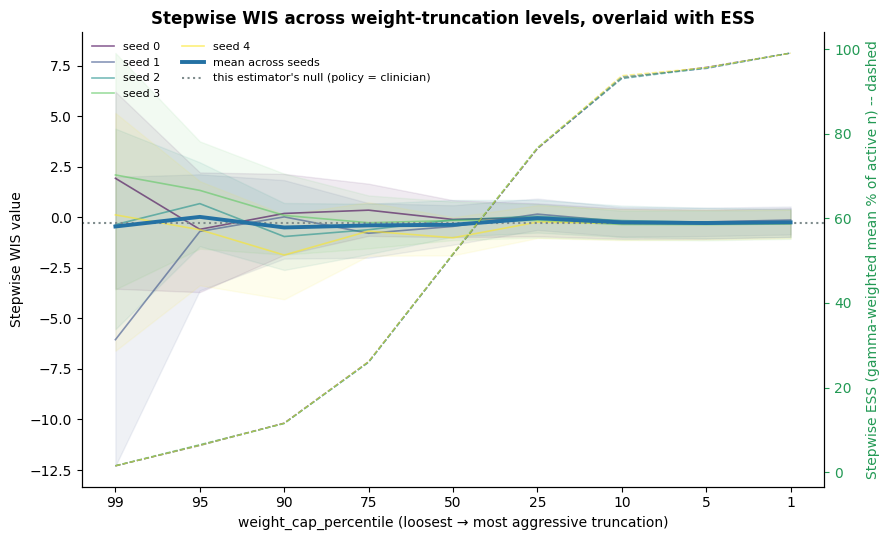

In [8]:
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
sweep = wis.run_weight_truncation_sweep_for_models(cql_models, bc_models, store, caps, split="val",
                                                   n_bootstrap=300, cache_dir=wis_cache)
wis.plot_weight_truncation_sweep(sweep, estimator="trajectory");
wis.plot_weight_truncation_sweep(sweep, estimator="stepwise")

In [9]:
from src.rl.evaluate_fqe_final_seeds import _by_seed
cql_by = _by_seed(cql_models)

def trajs(seed, fname):
    d = np.load(os.path.join(wis_cache, fname.format(seed=seed)))
    p = store.processor(cql_by[seed], "val")
    return wis.build_trajectory_data(p, d["behavior_lp"], d["target_lp"])[0]

sets = {"CQL 0.0325": "wis_logprobs_alpha0.0325_val_seed{seed}.npz",
        "BC cross control": "wis_control_cross_val_seed{seed}.npz"}
for name, fn in sets.items():
    print(f"\n#### {name}")
    for seed in sorted(cql_by):
        T = trajs(seed, fn)
        rows, rho = wis.log_weight_profile(T, gamma)
        print(f"seed {seed}: Spearman(total log-ratio vs length / return / mortality) = "
              f"{rho['length']:+.2f} / {rho['return']:+.2f} / {rho['mortality']:+.2f}")
        for H in (24, 48):
            n, null, diffs = wis.fixed_horizon_wis(T, gamma, H, (25, 50, 75, 90))
            print(f"   first {H}h of {n} stays (null {null:+.2f}): " + "  ".join(f"cap{c}: {d:+.2f}" for c, d in diffs.items()))


#### CQL 0.0325
seed 0: Spearman(total log-ratio vs length / return / mortality) = -0.59 / +0.24 / -0.04
   first 24h of 948 stays (null -0.95): cap25: -0.14  cap50: -0.19  cap75: +0.07  cap90: +0.63
   first 48h of 799 stays (null -1.95): cap25: -0.09  cap50: -0.37  cap75: +0.41  cap90: +0.80
seed 1: Spearman(total log-ratio vs length / return / mortality) = -0.59 / +0.23 / -0.06
   first 24h of 948 stays (null -0.95): cap25: -0.12  cap50: -0.29  cap75: -0.13  cap90: +0.57
   first 48h of 799 stays (null -1.95): cap25: -0.34  cap50: -0.39  cap75: -0.23  cap90: -0.07
seed 2: Spearman(total log-ratio vs length / return / mortality) = -0.59 / +0.24 / -0.06
   first 24h of 948 stays (null -0.95): cap25: +0.01  cap50: +0.31  cap75: +0.16  cap90: -0.33
   first 48h of 799 stays (null -1.95): cap25: -0.17  cap50: -0.63  cap75: -0.00  cap90: -0.04
seed 3: Spearman(total log-ratio vs length / return / mortality) = -0.59 / +0.25 / -0.06
   first 24h of 948 stays (null -0.95): cap25: -0.16  cap

## Log-ratio decomposition: where does the CQL policy lose density?

**Question.** The WIS weight of a stay is the product over hours of (policy density / behaviour density) on the logged action. For the CQL policy that product is very small on average (the log-ratio is negative every hour), so almost no stays overlap with the policy. The decomposition shows where that comes from.

**What is split.** At every logged hour, the per-hour log-ratio is the sum of four parts:
- fluid gate: did the policy and BC agree on whether to give fluid at all?
- fluid magnitude: given fluid was given, how likely was the logged dose under the policy vs BC?
- vaso gate, vaso magnitude: the same for vasopressor.
The magnitude part is 0 when that drug was not given. The four parts add up to exactly the log-ratio WIS uses (checked against the cached log-probabilities). Both densities use the final consistent scoring (plain gate, same clips).

**Table 1: by drug and by what the clinician did.** Rows are fluid and vaso, each split into "clinician gave" and "clinician withheld". Columns:
- mean and median log-ratio, and its gate and magnitude parts;
- share of the negative log-ratio mass (how much of the total density loss falls in that group);
- the policy's and BC's mean fire probability;
- the median dose of the policy, BC and the clinician.
If "gave" rows carry most of the negative mass, the policy withholds where clinicians act. If "withheld" rows do, the policy treats where clinicians do not.

**Table 2: stay level.** For each of the four parts, the per-stay sum of that part and its variance share, Cov(part, stay total) / Var(stay total), which add up to 1 across the four parts. It shows which part spreads the stay weights. It also gives each part's rank correlation with stay length.

**Plot.** (a) the share of negative mass per group, one dot per seed; (b) the variance share per part.

seed 0: parts loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_decomp_alpha0.0325_val_seed0.npz
   check: parts add up to the WIS log-ratio, max |difference| 7.63e-06
seed 1: parts loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_decomp_alpha0.0325_val_seed1.npz
   check: parts add up to the WIS log-ratio, max |difference| 9.42e-06
seed 2: parts loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_decomp_alpha0.0325_val_seed2.npz
   check: parts add up to the WIS log-ratio, max |difference| 9.54e-06
seed 3: parts loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_decomp_alpha0.0325_val_seed3.npz
   check: parts add up to the WIS log-ratio, max |difference| 7.15e-06
seed 4: parts loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_decomp_alpha0.0325_val_seed4.npz
   check: parts add up to the WIS log-ratio, max |d

n  frac_rows  mean_lr  median_lr  mean_gate_lr  \
drug  clinician                                                          
fluid gave       126040.0      0.724   -1.787     -0.135         0.289   
      withheld    48013.0      0.276  -17.924    -18.395       -17.924   
vaso  gave        34149.0      0.196   -4.169     -2.887        -0.390   
      withheld   139904.0      0.804   -0.069      0.007        -0.069   

                 mean_mag_lr  share_neg_mass  share_pos_mass  policy_fire_p  \
drug  clinician                                                               
fluid gave            -2.076           0.206           0.772          1.000   
      withheld         0.000           0.667           0.000          0.994   
vaso  gave            -3.778           0.116           0.139          0.669   
      withheld         0.000           0.011           0.089          0.079   

                 bc_fire_p  policy_dose_median  bc_dose_median  \
drug  clinician                                                  
fluid gave           0.857               0.327           0.337   
      withheld       0.108               0.029           0.193   
vaso  gave           0.733               0.132           0.334   
      withheld       0.068               0.048           0.149   

                 logged_dose_median  share_neg_mass_min  share_neg_mass_max  \
drug  clinician                                                               
fluid gave                    0.340               0.188               0.245   
      withheld                  NaN               0.629               0.690   
vaso  gave                    0.345               0.100               0.144   
      withheld                  NaN               0.009               0.014   

                 mean_lr_min  mean_lr_max  
drug  clinician                            
fluid gave            -2.372       -1.513  
      withheld       -18.193      -17.575  
vaso  gave            -5.189       -3.572  
      withheld        -0.101       -0.051

,mean_stay_sum,sd_stay_sum,variance_share,spearman_length
component,,,,
fluid_gate,-818.461,1860.790,0.814,-0.256
fluid_mag,-259.837,662.713,0.129,-0.418
vaso_gate,-22.796,63.144,0.007,-0.178
vaso_mag,-128.133,397.286,0.049,-0.346
total,-1229.226,2071.515,1.000,-0.588


Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/decomposition_alpha0.0325.png


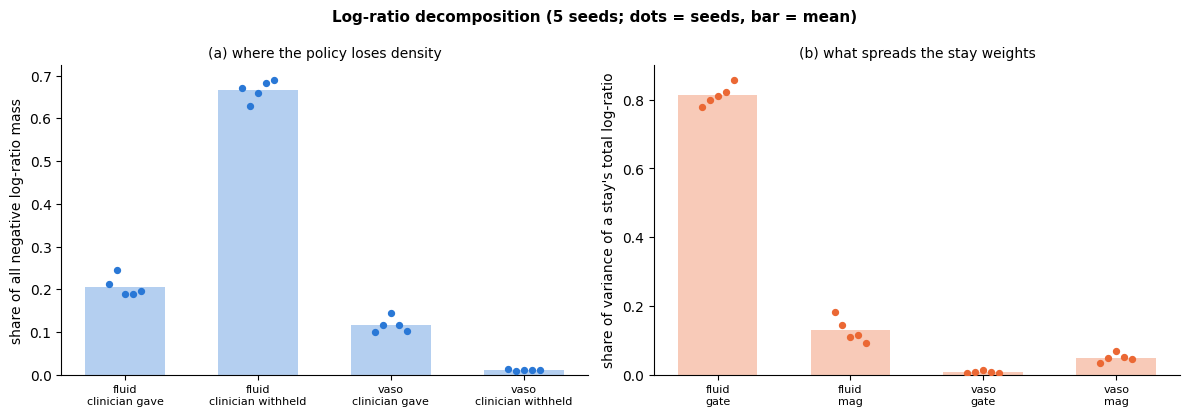

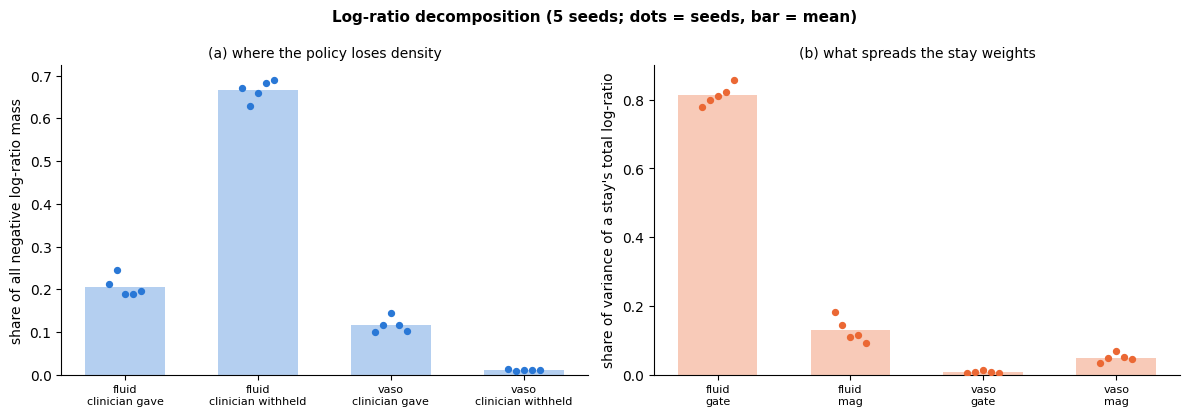

In [15]:
decomp = wis.run_decomposition_for_models(cql_models, bc_models, store, split="val", cache_dir=wis_cache)
group_mean, stay_mean = wis.summarize_decomposition(decomp)
display(group_mean.round(3))
display(stay_mean.round(3))
wis.plot_decomposition(decomp, save_path=os.path.join(wis_cache, "decomposition_alpha0.0325.png"))

In [16]:
from scipy.special import expit
seed = 0
d = np.load(os.path.join(wis_cache, f"wis_decomp_alpha0.0325_val_seed{seed}.npz"))
A = np.asarray(wis._to_numpy(store.processor(_by_seed(cql_models)[seed], "val").rl_dataset["actions"]))
for drug, col in (("fluid", 0), ("vaso", 1)):
    withheld = A[:, col] <= 1e-4
    pol_dose, bc_dose = expit(d[f"{drug}_mean_cql"]), expit(d[f"{drug}_mean_bc"])
    pol_fire = d[f"{drug}_p_cql"] > 0.5
    print(f"{drug}: policy gate>0.5 on {pol_fire.mean():.3f} of all hours, {pol_fire[withheld].mean():.3f} of clinician-withheld hours")
    for tau in (0.01, 0.02, 0.05, 0.1):
        print(f"   tau {tau}: policy dose below tau on {(pol_dose[withheld] < tau).mean():.2f} of withheld hours | BC's own dose: {(bc_dose[withheld] < tau).mean():.2f}")
    print("   clinician nonzero dose percentiles (1, 5, 10, 25, 50):", np.percentile(A[~withheld, col], [1, 5, 10, 25, 50]).round(3))

fluid: policy gate>0.5 on 0.999 of all hours, 0.998 of clinician-withheld hours
   tau 0.01: policy dose below tau on 0.42 of withheld hours | BC's own dose: 0.00
   tau 0.02: policy dose below tau on 0.47 of withheld hours | BC's own dose: 0.00
   tau 0.05: policy dose below tau on 0.56 of withheld hours | BC's own dose: 0.00
   tau 0.1: policy dose below tau on 0.64 of withheld hours | BC's own dose: 0.00
   clinician nonzero dose percentiles (1, 5, 10, 25, 50): [0.129 0.162 0.162 0.238 0.34 ]
vaso: policy gate>0.5 on 0.204 of all hours, 0.073 of clinician-withheld hours
   tau 0.01: policy dose below tau on 0.00 of withheld hours | BC's own dose: 0.00
   tau 0.02: policy dose below tau on 0.00 of withheld hours | BC's own dose: 0.00
   tau 0.05: policy dose below tau on 0.57 of withheld hours | BC's own dose: 0.00
   tau 0.1: policy dose below tau on 0.96 of withheld hours | BC's own dose: 0.02
   clinician nonzero dose percentiles (1, 5, 10, 25, 50): [0.07  0.171 0.188 0.253 0.345]

{'fluid': 0.1, 'vaso': 0.05} _tauf0.1-v0.05
gamma = 0.975 (CQL models' saved discount)
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=-0.335 (traj ESS 98.9%)  step=-0.175 (step ESS 99.0%)  [nulls -0.381 / -0.275]
  wcap=  5.0  traj=-0.130 (traj ESS 94.9%)  step=-0.027 (step ESS 95.2%)  [nulls -0.381 / -0.275]
  wcap= 10.0  traj=0.109 (traj ESS 90.0%)  step=0.173 (step ESS 90.6%)  [nulls -0.381 / -0.275]
  wcap= 25.0  traj=0.663 (traj ESS 75.1%)  step=0.316 (step ESS 76.6%)  [nulls -0.381 / -0.275]
  wcap= 50.0  traj=2.190 (traj ESS 50.1%)  step=0.094 (step ESS 52.2%)  [nulls -0.381 / -0.275]
  wcap= 75.0  traj=3.712 (traj ESS 25.9%)  step=0.498 (step ESS 27.6%)  [nulls -0.381 / -0.275]
  wcap= 90.0  traj=4.227 (traj ESS 10.7%)  step=0.580 (step ESS 12.4%)  [nulls -0.381 / -0.275]
  wcap= 95.0  traj=4.245 (traj ESS 5.7%)  step=-0.246 (step ESS 6.7%)

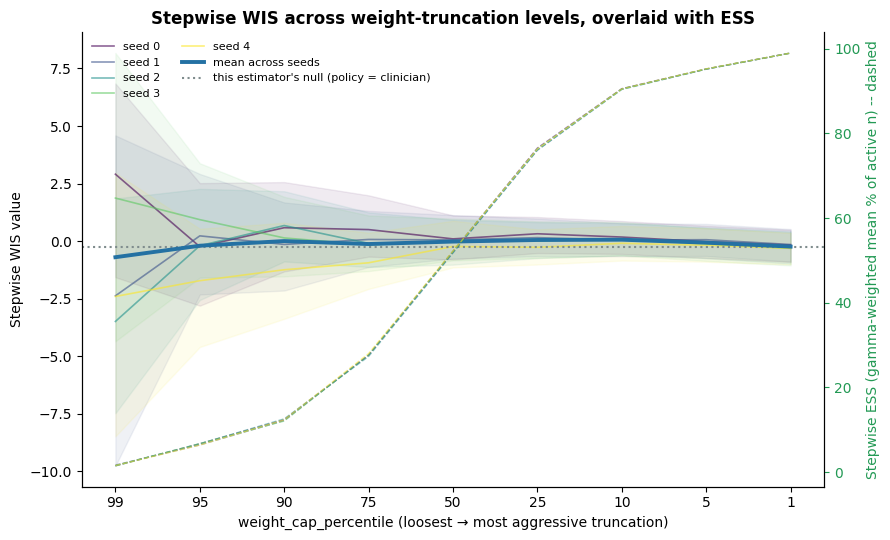

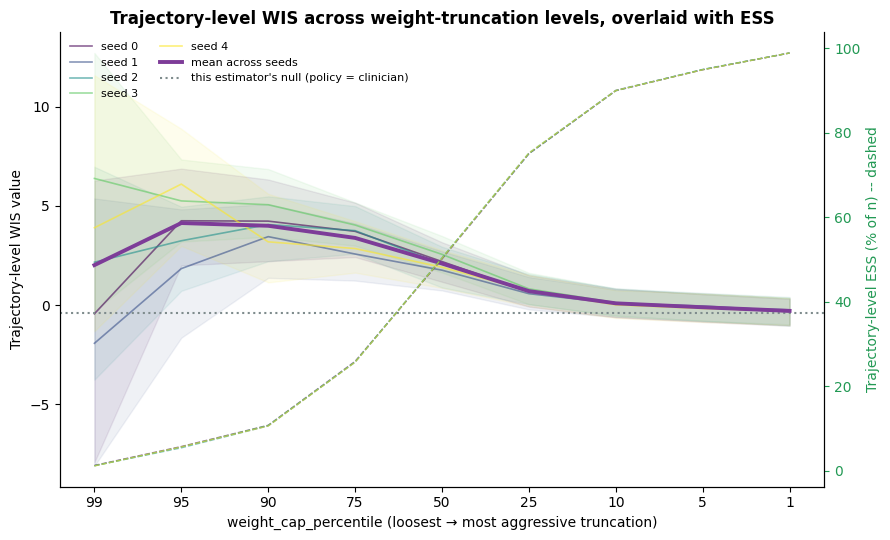

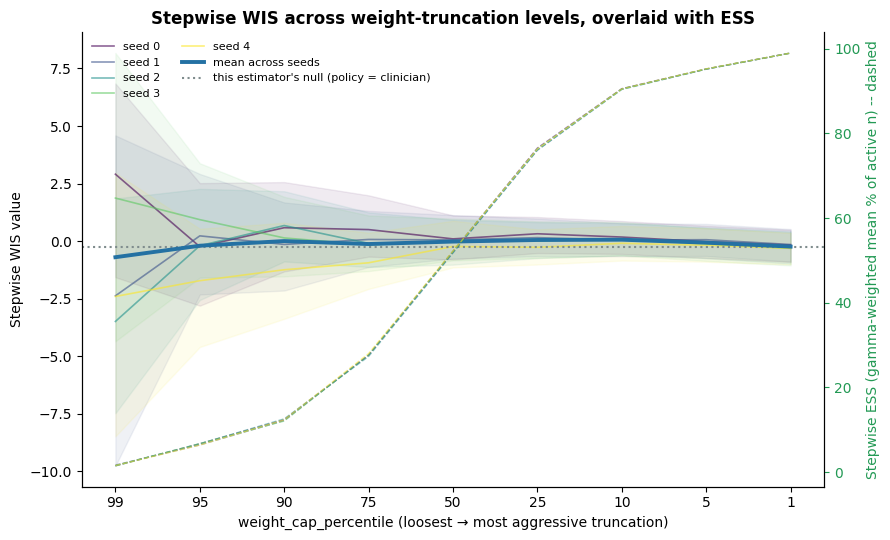

In [17]:
wis.ACTION_COARSENING = {"fluid": 0.1, "vaso": 0.05}
print(wis.ACTION_COARSENING, wis._coarsening_suffix())   # should print the dict and _tauf0.1-v0.05

caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
sweep = wis.run_weight_truncation_sweep_for_models(cql_models, bc_models, store, caps, split="val",
                                                   n_bootstrap=300, cache_dir=wis_cache)
wis.plot_weight_truncation_sweep(sweep, estimator="trajectory");
wis.plot_weight_truncation_sweep(sweep, estimator="stepwise")

seed 0: computing parts
   check: parts add up to the WIS log-ratio, max |difference| 7.15e-06
seed 1: computing parts
   check: parts add up to the WIS log-ratio, max |difference| 9.42e-06
seed 2: computing parts
   check: parts add up to the WIS log-ratio, max |difference| 9.78e-06
seed 3: computing parts
   check: parts add up to the WIS log-ratio, max |difference| 6.56e-06
seed 4: computing parts
   check: parts add up to the WIS log-ratio, max |difference| 7.99e-06


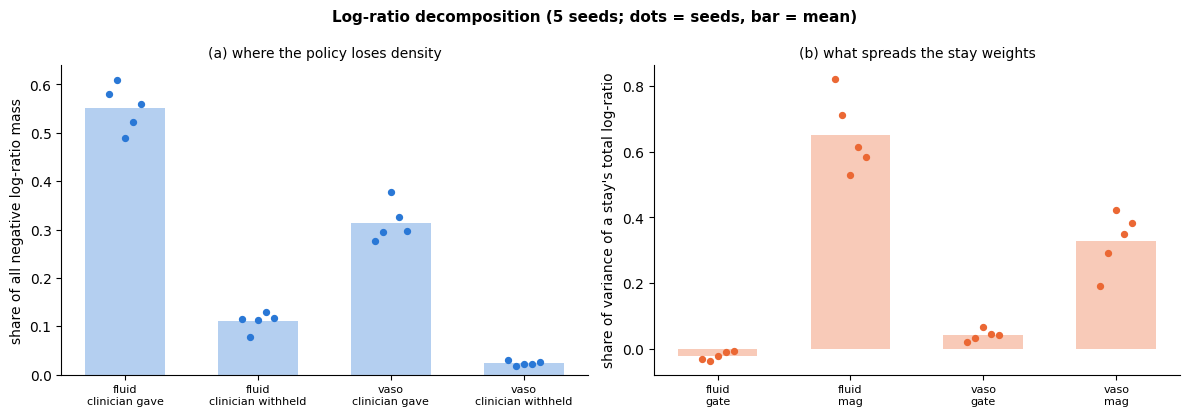

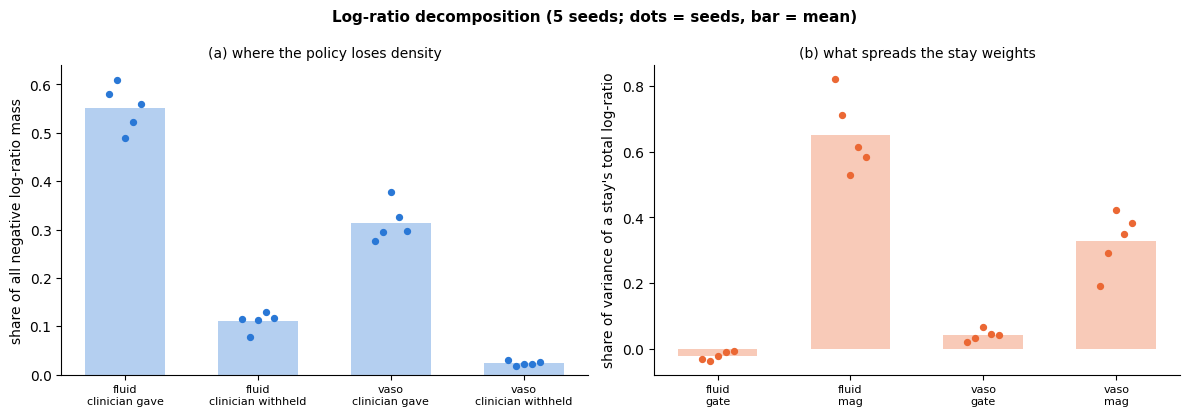

In [19]:
decomp = wis.run_decomposition_for_models(cql_models, bc_models, store, split="val", cache_dir=wis_cache)
wis.summarize_decomposition(decomp)
wis.plot_decomposition(decomp, save_path=None)

In [20]:
import pandas as pd
pd.set_option("display.width", 250, "display.max_columns", 50, "display.float_format", "{:.3f}".format)

out = wis.summarize_decomposition(decomp)
for name, df in (out.items() if isinstance(out, dict) else enumerate(out if isinstance(out, (tuple, list)) else [out])):
    print(f"\n=== {name} ===")
    print(df.to_string())


=== 0 ===
                         n  frac_rows  mean_lr  median_lr  mean_gate_lr  mean_mag_lr  share_neg_mass  share_pos_mass  policy_fire_p  bc_fire_p  policy_dose_median  bc_dose_median  logged_dose_median  share_neg_mass_min  share_neg_mass_max  mean_lr_min  mean_lr_max
drug  clinician                                                                                                                                                                                                                                                         
fluid gave      125186.000      0.719   -1.787     -0.136         0.282       -2.070           0.552           0.742          1.000      0.859               0.327           0.338               0.342               0.489               0.609       -2.364       -1.504
      withheld   48867.000      0.281   -1.021      0.005        -1.021        0.000           0.111           0.041          0.994      0.116               0.031           0.194                

# doubly robust estimator
What it computes. The estimator is a weighted per-decision doubly robust (DR) estimate. It uses the same cumulative weights and the same per-hour upper-tail cap as your stepwise WIS, plus the FQE critic of the same seed.

Critic term: the critic’s Q at the logged action corrects the weights, and Q at the policy’s own action supplies the baseline.
Comparison: dr_minus_null is DR minus the stepwise null, so it is on the same scale as your “policy − null” columns.
Units: the critic is converted to reward units with its reward_scale.

In [21]:
from src.rl import evaluate_doubly_robust as DR
fqe_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/fqe/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds"      # root of the FQE critics (seeds 0-4)
fqe_study   = R.make_study(fqe_dir, family="fqe", group_by=())
fqe_models   = M.load_study_models(fqe_study)            # {(): {seed: LoadedModel}}

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/fqe/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.2 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: critic)
  loaded LoadedModel(seed 1: critic)
  loaded LoadedModel(seed 2: critic)
  loaded LoadedModel(seed 3: critic)
  loaded LoadedModel(seed 4: critic)


{'fluid': 0.1, 'vaso': 0.05}
gamma = 0.975 (CQL models' saved discount)
action coarsening: {'fluid': 0.1, 'vaso': 0.05}

=== Seed 0 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_tauf0.1-v0.05_val_seed0.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 0: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  cap    10: DR - null +1.703 [+1.413, +1.972]   IS - null +0.448 [+0.241, +0.655]   critic alone V_pi - G0 +0.553
  cap    25: DR - null +1.290 [+0.915, +1.702]   IS - null +0.591 [+0.257, +0.961]   critic alone V_pi - G0 +0.553
  cap    50: DR - null +0.759 [+0.194, +1.494]   IS - null +0.368 [-0.227, +1.080]   critic alone V_pi - G0 +0.553

=== Seed 1 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_tauf0.1-v0.05_val_seed1.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 1: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  cap    10: DR - null +2.075 [+1.750, +2.418]   IS - null +0.316 [+0.061, +0.550]   critic alone V_pi - G0 +0.383
  cap    25: DR - null +1.488 [+1.070, +1.967]   IS - null +0.423 [+0.008, +0.865]   critic alone V_pi - G0 +0.383
  cap    50: DR - null +0.830 [+0.070, +1.648]   IS - null +0.324 [-0.354, +1.085]   critic alone V_pi - G0 +0.383

=== Seed 2 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_tauf0.1-v0.05_val_seed2.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 2: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


... (2 outputs left out)

  cap    10: DR - null +2.159 [+1.888, +2.372]   IS - null +0.377 [+0.201, +0.566]   critic alone V_pi - G0 +2.782
  cap    25: DR - null +1.432 [+1.093, +1.872]   IS - null +0.272 [-0.075, +0.627]   critic alone V_pi - G0 +2.782
  cap    50: DR - null +0.768 [+0.089, +1.557]   IS - null +0.267 [-0.344, +1.005]   critic alone V_pi - G0 +2.782

=== Seed 4 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_tauf0.1-v0.05_val_seed4.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 4: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  cap    10: DR - null +1.654 [+1.376, +1.958]   IS - null +0.177 [-0.043, +0.396]   critic alone V_pi - G0 +1.282
  cap    25: DR - null +1.006 [+0.584, +1.389]   IS - null +0.002 [-0.394, +0.365]   critic alone V_pi - G0 +1.282
  cap    50: DR - null +0.480 [-0.167, +1.241]   IS - null +0.040 [-0.568, +0.759]   critic alone V_pi - G0 +1.282


,dr_mean,dr_min,dr_max,dr_seeds_ci_above_0,is_mean,is_min,is_max,critic_alone_mean,n_seeds
cap,,,,,,,,,
10,1.997,1.654,2.397,5,0.333,0.177,0.448,1.587,5
25,1.376,1.006,1.663,5,0.320,0.002,0.591,1.587,5
50,0.772,0.480,1.025,4,0.251,0.040,0.368,1.587,5


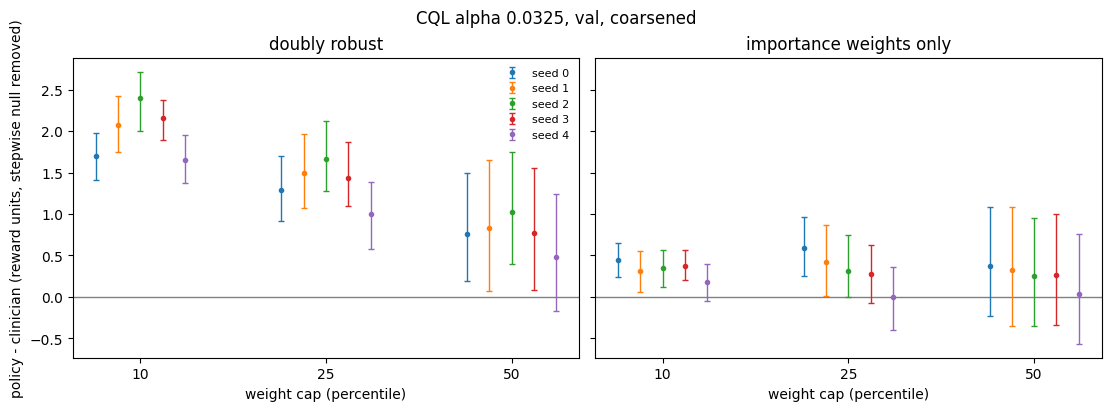

In [23]:
print(wis.ACTION_COARSENING)
dr_df = DR.run_doubly_robust(cql_models, bc_models, fqe_models, store, split="val",
                             wcap_values=(10, 25, 50), cache_dir=wis_cache,
                             n_boot=200)   
display(DR.summarize_doubly_robust(dr_df))
DR.plot_doubly_robust(dr_df, title="CQL alpha 0.0325, val, coarsened");

In [25]:
# load sarsa models
basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/"
print(f"Using basic_q_dir: {basic_q_dir}")

sarsa_hs_dir = os.path.join(basic_q_dir, "with_actions", "health_score_change_only", "five_seeds")
print(f"Using sarsa_hs_dir: {sarsa_hs_dir}")
sarsa_hs_study = R.make_study(sarsa_hs_dir, name="SARSA (health score)")
_ = sarsa_hs_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})
sarsa_models   = M.load_study_models(sarsa_hs_study)  

Using basic_q_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/
Using sarsa_hs_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.2 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
Study 'SARSA (health score)': 1 group(s), 5 run(s), seeds [0, 1, 2, 3, 4]
  OK
  loaded LoadedModel(SARSA (health score) seed 0: critic)
  loaded LoadedModel(SARSA (health score) seed 1: critic)
  loaded LoadedModel(SARSA (health score) seed 2: critic)
  loaded LoadedModel(SARSA (health score) seed 3: critic)
  

{'fluid': 0.1, 'vaso': 0.05}
gamma = 0.975 (CQL models' saved discount)
action coarsening: {'fluid': 0.1, 'vaso': 0.05}

=== Seed 0 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_tauf0.1-v0.05_val_seed0.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 0: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  unit check: SARSA V_mu +0.204 vs observed return G0 -0.381 (reward units)
  cap    10: DR - null +1.703 [+1.413, +1.972]   IS - null +0.448 [+0.241, +0.655]   critic alone V_pi - G0 +0.553
  cap    25: DR - null +1.290 [+0.915, +1.702]   IS - null +0.591 [+0.257, +0.961]   critic alone V_pi - G0 +0.553
  cap    50: DR - null +0.759 [+0.194, +1.494]   IS - null +0.368 [-0.227, +1.080]   critic alone V_pi - G0 +0.553
  cap    75: DR - null +0.995 [+0.108, +2.036]   IS - null +0.772 [-0.108, +1.845]   critic alone V_pi - G0 +0.553
  cap    90: DR - null +1.263 [-0.438, +3.221]   IS - null +0.854 [-1.006, +2.729]   critic alone V_pi - G0 +0.553

=== Seed 1 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_tauf0.1-v0.05_val_seed1.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 1: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  unit check: SARSA V_mu -0.058 vs observed return G0 -0.381 (reward units)
  cap    10: DR - null +2.075 [+1.750, +2.418]   IS - null +0.316 [+0.061, +0.550]   critic alone V_pi - G0 +0.383
  cap    25: DR - null +1.488 [+1.070, +1.967]   IS - null +0.423 [+0.008, +0.865]   critic alone V_pi - G0 +0.383
  cap    50: DR - null +0.830 [+0.070, +1.648]   IS - null +0.324 [-0.354, +1.085]   critic alone V_pi - G0 +0.383
  cap    75: DR - null +0.805 [-0.270, +1.809]   IS - null +0.343 [-0.765, +1.356]   critic alone V_pi - G0 +0.383
  cap    90: DR - null +0.768 [-1.035, +2.473]   IS - null +0.127 [-1.520, +1.676]   critic alone V_pi - G0 +0.383

=== Seed 2 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_tauf0.1-v0.05_val_seed2.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 2: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


... (2 outputs left out)

  unit check: SARSA V_mu -0.641 vs observed return G0 -0.381 (reward units)
  cap    10: DR - null +2.159 [+1.888, +2.372]   IS - null +0.377 [+0.201, +0.566]   critic alone V_pi - G0 +2.782
  cap    25: DR - null +1.432 [+1.093, +1.872]   IS - null +0.272 [-0.075, +0.627]   critic alone V_pi - G0 +2.782
  cap    50: DR - null +0.768 [+0.089, +1.557]   IS - null +0.267 [-0.344, +1.005]   critic alone V_pi - G0 +2.782
  cap    75: DR - null +0.466 [-0.549, +1.550]   IS - null +0.109 [-0.866, +1.199]   critic alone V_pi - G0 +2.782
  cap    90: DR - null +0.867 [-0.419, +2.742]   IS - null +0.410 [-1.020, +2.146]   critic alone V_pi - G0 +2.782

=== Seed 4 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/wis_cache/wis_logprobs_alpha0.0325_tauf0.1-v0.05_val_seed4.npz


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 4: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  unit check: SARSA V_mu +0.803 vs observed return G0 -0.381 (reward units)
  cap    10: DR - null +1.654 [+1.376, +1.958]   IS - null +0.177 [-0.043, +0.396]   critic alone V_pi - G0 +1.282
  cap    25: DR - null +1.006 [+0.584, +1.389]   IS - null +0.002 [-0.394, +0.365]   critic alone V_pi - G0 +1.282
  cap    50: DR - null +0.480 [-0.167, +1.241]   IS - null +0.040 [-0.568, +0.759]   critic alone V_pi - G0 +1.282
  cap    75: DR - null -0.389 [-1.412, +0.585]   IS - null -0.671 [-1.666, +0.310]   critic alone V_pi - G0 +1.282
  cap    90: DR - null -0.713 [-2.359, +1.112]   IS - null -0.973 [-2.632, +0.779]   critic alone V_pi - G0 +1.282


,dr_mean,dr_min,dr_max,dr_seeds_ci_above_0,is_mean,is_min,is_max,critic_alone_mean,n_seeds
cap,,,,,,,,,
10,1.997,1.654,2.397,5,0.333,0.177,0.448,1.587,5
25,1.376,1.006,1.663,5,0.320,0.002,0.591,1.587,5
50,0.772,0.480,1.025,4,0.251,0.040,0.368,1.587,5
75,0.530,-0.389,0.995,1,0.145,-0.671,0.772,1.587,5
90,0.685,-0.713,1.263,0,0.273,-0.973,0.949,1.587,5


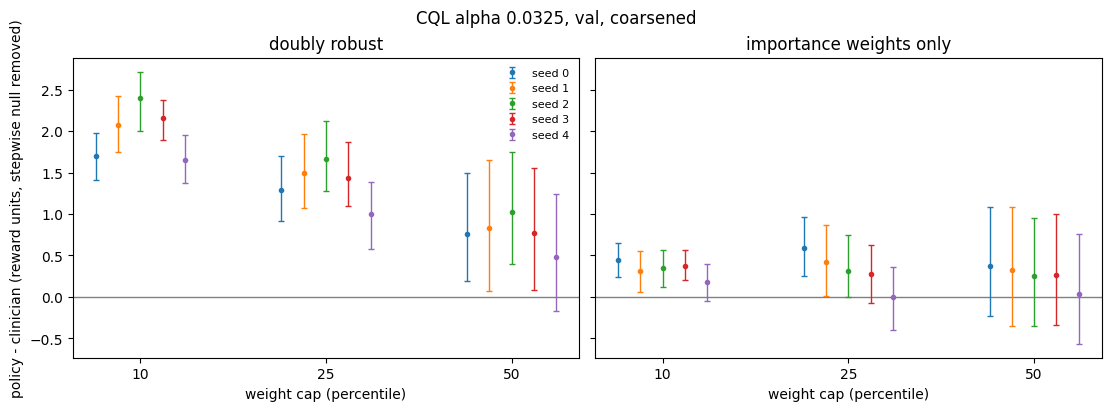

In [ ]:
print(wis.ACTION_COARSENING)
dr_df2 = DR.run_doubly_robust(cql_models, bc_models, fqe_models, store, split="val",
                              wcap_values=(10, 25, 50, 75, 90), cache_dir=wis_cache, n_boot=200,
                              sarsa_models=sarsa_models)
display(DR.summarize_doubly_robust(dr_df2))
DR.plot_doubly_robust(dr_df2, title="CQL alpha 0.0325, val, coarsened");

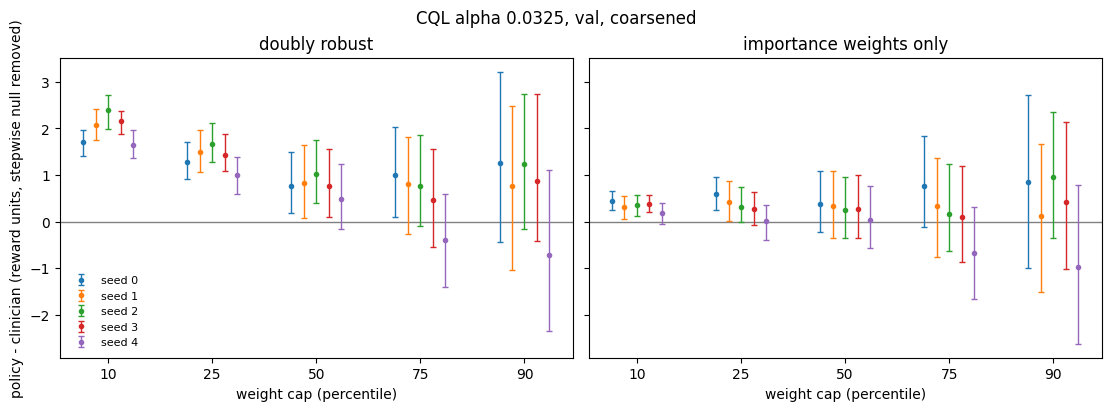

In [27]:
DR.plot_doubly_robust(dr_df2, title="CQL alpha 0.0325, val, coarsened");

# bc vs bc control

  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
seed 0 (target BC 0): mean log-ratio per hour +0.117
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=-0.377 (traj ESS 99.9%)  step=-0.280 (step ESS 99.8%)  [nulls -0.381 / -0.275]
  wcap=  5.0  traj=-0.415 (traj ESS 99.0%)  step=-0.280 (step ESS 99.0%)  [nulls -0.381 / -0.275]
  wcap= 10.0  traj=-0.573 (traj ESS 96.7%)  step=-0.271 (step ESS 98.1%)  [nulls -0.381 / -0.275]
  wcap= 25.0  traj=-1.771 (traj ESS 81.7%)  step=-0.280 (step ESS 94.3%)  [nulls -0.38

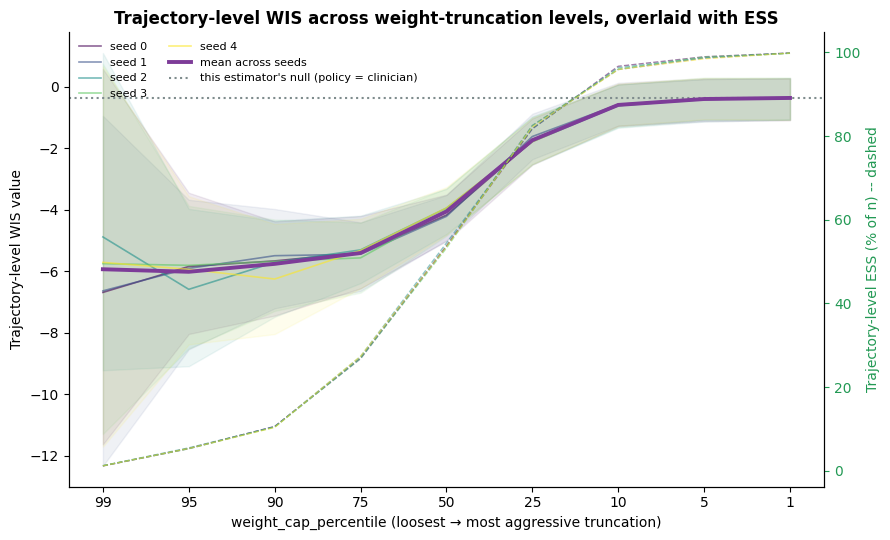

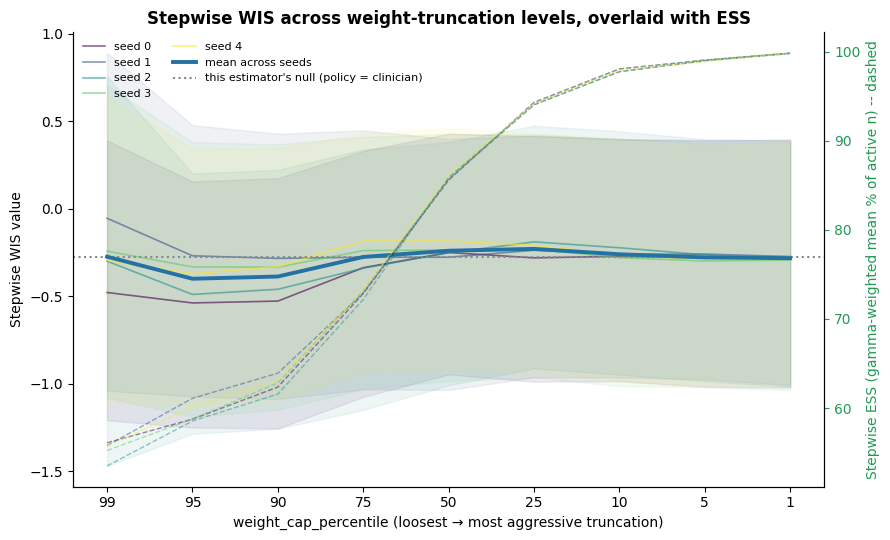

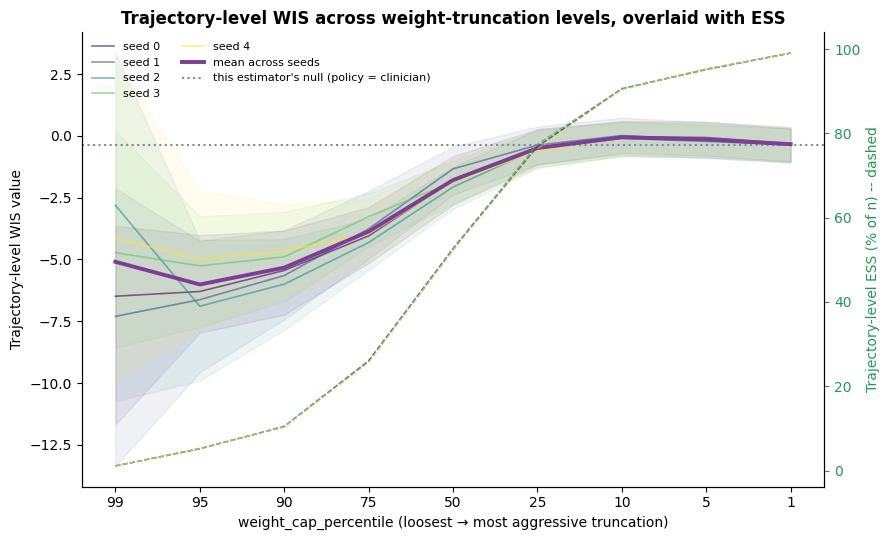

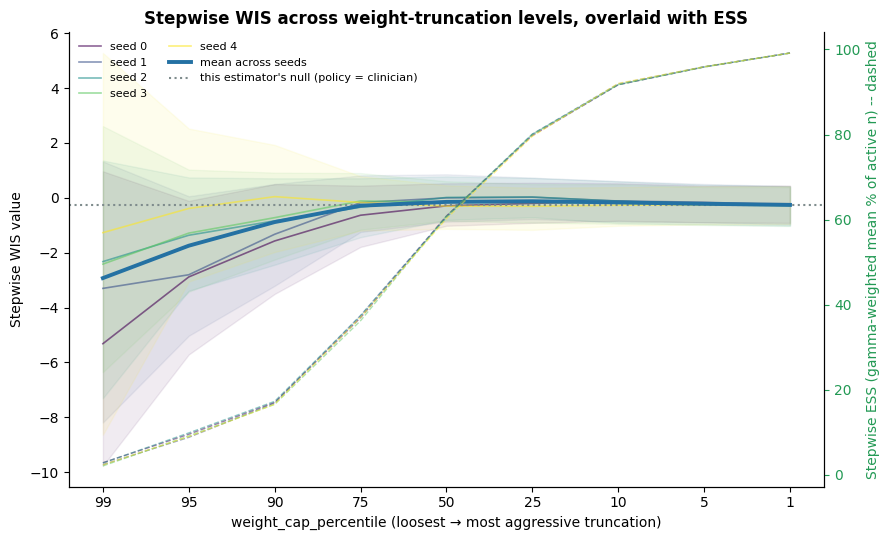

In [8]:
gamma = wis.discount_from_models(cql_models)
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]

ctrl_self  = wis.run_bc_control_sweep(bc_models, store, caps, gamma, mode="self",  split="val", cache_dir=wis_cache)
ctrl_cross = wis.run_bc_control_sweep(bc_models, store, caps, gamma, mode="cross", split="val", cache_dir=wis_cache)

for name, rows in (("self", ctrl_self), ("cross-seed", ctrl_cross)):
    print(f"\n######## control: {name}")
    wis.plot_weight_truncation_sweep(rows, estimator="trajectory")
    wis.plot_weight_truncation_sweep(rows, estimator="stepwise")

In [8]:
import pandas as pd
gamma = wis.discount_from_models(cql_models)
res = wis.run_wis_for_models(cql_models, bc_models, store, split="val", n_bootstrap=100, include_myopic=False)

for r in res:
    rows, rho = wis.log_weight_profile(r["trajectories"], gamma)
    print("seed", r["seed"], "Spearman(log-weight, .):", {k: round(v, 2) for k, v in rho.items()})
    if r["seed"] == res[0]["seed"]:
        display(pd.DataFrame(rows).round(2))

for H in (24, 48, 96):
    for r in res:
        n, null, diffs = wis.fixed_horizon_wis(r["trajectories"], gamma, H, caps)
        print(f"H={H} seed {r['seed']} (n={n}, null {null:.2f}): " + "  ".join(f"cap{c}:{d:+.2f}" for c, d in diffs.items()))

gamma = 0.975 (CQL models' saved discount)

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: -20.1190  [-20.1190, 6.6571]  ESS=1.0/1007 (0.1%)
  Stepwise WIS:         -10.6093  [-19.4556, 10.5499]
  Minus null (policy = clinician): trajectory -19.738 [-20.330, +7.232]   stepwise -10.335 [-19.054, +10.799]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: -0.3813 +/- 0.3511 (SEM)
  Trajectory-level WIS: -4.1949  [-4.2014, 8.4644]  ESS=1.0/1007 (0.1%)
  Stepwise WIS:         -19.4355  [-24.9328, 0.6039]
  Minus null (policy = clinician): trajectory -3.814 [-4.451, +8.741]   stepwise -19.161 [-24.807, +0.339]  (nulls -0.381 / -0.275)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 99.8%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: -0

,bin,n,mean_log_w,log_ratio_per_step,median_length,mortality,mean_return
0,0,101,-6530.08,-14.94,438.0,0.27,-5.28
1,1,101,-2283.60,-13.03,168.0,0.30,-2.50
2,2,101,-1268.07,-10.90,139.0,0.20,-0.88
3,3,101,-803.09,-8.14,124.0,0.33,-0.19
4,4,101,-507.29,-7.66,98.0,0.15,0.90
5,5,101,-335.86,-4.44,109.0,0.25,0.12
6,6,101,-212.96,-4.02,85.0,0.29,-0.61
7,7,100,-126.32,-3.09,77.0,0.25,0.60
8,8,100,-57.76,-1.42,49.5,0.24,0.68
9,9,100,2.12,-0.09,53.5,0.16,3.40


seed 1 Spearman(log-weight, .): {'length': -0.57, 'return': 0.22, 'mortality': -0.05}
seed 2 Spearman(log-weight, .): {'length': -0.57, 'return': 0.23, 'mortality': -0.05}
seed 3 Spearman(log-weight, .): {'length': -0.57, 'return': 0.24, 'mortality': -0.06}
seed 4 Spearman(log-weight, .): {'length': -0.55, 'return': 0.2, 'mortality': -0.03}
H=24 seed 0 (n=948, null -0.95): cap1:-0.02  cap5:+0.01  cap10:+0.03  cap25:-0.14  cap50:-0.18  cap75:+0.10  cap90:+0.63  cap95:+1.37  cap99:+2.55
H=24 seed 1 (n=948, null -0.95): cap1:+0.01  cap5:-0.04  cap10:-0.02  cap25:-0.11  cap50:-0.30  cap75:-0.23  cap90:+0.69  cap95:-0.34  cap99:+0.06
H=24 seed 2 (n=948, null -0.95): cap1:-0.06  cap5:-0.01  cap10:+0.08  cap25:+0.01  cap50:+0.32  cap75:+0.02  cap90:-0.60  cap95:+1.11  cap99:+2.45
H=24 seed 3 (n=948, null -0.95): cap1:-0.05  cap5:-0.03  cap10:+0.02  cap25:-0.16  cap50:-0.19  cap75:-0.33  cap90:-0.21  cap95:+1.76  cap99:+4.01
H=24 seed 4 (n=948, null -0.95): cap1:-0.05  cap5:+0.10  cap10:+0.13 

In [7]:
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
meta = dict(split="val", caps=caps, gamma=wis.discount_from_models(cql_models), n_bootstrap=300, models=sig)
sweep = wis.cached_results(
    os.path.join(wis_dir, "wis_val_sweep.pkl"),
    lambda: wis.run_weight_truncation_sweep_for_models(cql_models, bc_models, store, caps, split="val",
                                                       n_bootstrap=300, cache_dir=wis_dir),
    meta)

gamma = 0.975 (CQL models' saved discount)
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=0.981 (traj ESS 98.8%)  step=0.964 (step ESS 98.8%)
  wcap=  5.0  traj=1.135 (traj ESS 95.0%)  step=1.102 (step ESS 95.0%)
  wcap= 10.0  traj=1.002 (traj ESS 90.0%)  step=1.253 (step ESS 90.2%)
  wcap= 25.0  traj=1.157 (traj ESS 75.0%)  step=1.646 (step ESS 75.5%)
  wcap= 50.0  traj=0.896 (traj ESS 50.0%)  step=2.142 (step ESS 51.4%)
  wcap= 75.0  traj=0.592 (traj ESS 25.0%)  step=3.408 (step ESS 26.5%)
  wcap= 90.0  traj=1.838 (traj ESS 10.3%)  step=3.658 (step ESS 11.7%)
  wcap= 95.0  traj=0.488 (traj ESS 5.7%)  step=4.488 (step ESS 6.5%)
  wcap= 99.0  traj=2.549 (traj ESS 1.3%)  step=7.962 (step ESS 1.7%)
CQL seeds loaded: [1]
BC seeds loaded:  [1]
Matched 1 (CQL, BC) pairs by results.json seed: [1]

=== Seed 1: building trajectories once, then sweeping 9 c

In [8]:
for r in results:
    null_traj = [dict(t, log_ratio=np.zeros_like(t["log_ratio"])) for t in r["trajectories"]]
    print(r["seed"], "stepwise null:", round(wis.compute_stepwise_wis(null_traj, 0.975)["value"], 3),
          "| trajectory null (= baseline):", round(wis.compute_trajectory_wis(null_traj, 0.975)["value"], 3))

0 stepwise null: 0.91 | trajectory null (= baseline): 0.883
1 stepwise null: 0.91 | trajectory null (= baseline): 0.883
2 stepwise null: 0.91 | trajectory null (= baseline): 0.883
3 stepwise null: 0.91 | trajectory null (= baseline): 0.883
4 stepwise null: 0.91 | trajectory null (= baseline): 0.883


In [9]:
def diff_table(results):
    rows = []
    for r in results:
        m = r["minus_null"]
        rows.append({"seed": r["seed"], "ess_frac": r["weight_diagnostics"]["ess_frac"],
                     "traj_diff": m["trajectory"]["diff"], "traj_lo": m["trajectory"]["ci_lower"], "traj_hi": m["trajectory"]["ci_upper"],
                     "step_diff": m["stepwise"]["diff"], "step_lo": m["stepwise"]["ci_lower"], "step_hi": m["stepwise"]["ci_upper"]})
    return pd.DataFrame(rows).round(3)

for cap in (25, 50):
    res = wis.run_wis_for_models(cql_models, bc_models, store, split="val", gamma=0.975,
                                 weight_cap_percentile=cap, include_myopic=False)
    print(f"\ncap {cap}"); display(diff_table(res))


=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.1570  [0.2180, 2.0321]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.6457  [0.7488, 2.5255]
  Minus null (policy = clinician): trajectory +0.274 [-0.241, +0.716]   stepwise +0.735 [+0.333, +1.108]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.0387  [0.1958, 1.9740]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.4233  [0.5388, 2.3634]
  Minus null (policy = clinician): trajectory +0.156 [-0.233, +0.653]   stepwise +0.513 [+0.135, +0.928]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.2478  [0.3365, 2.1010]  ES

,seed,ess_frac,traj_diff,traj_lo,traj_hi,step_diff,step_lo,step_hi
0,0,0.75,0.274,-0.241,0.716,0.735,0.333,1.108
1,1,0.75,0.156,-0.233,0.653,0.513,0.135,0.928
2,2,0.75,0.365,-0.210,0.773,0.727,0.321,1.124
3,3,0.75,0.041,-0.369,0.728,0.570,0.277,0.915
4,4,0.75,0.311,-0.188,0.789,0.818,0.433,1.211



=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 0.8961  [-0.2778, 1.8981]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         2.1425  [1.0565, 3.2538]
  Minus null (policy = clinician): trajectory +0.013 [-0.772, +0.742]   stepwise +1.232 [+0.543, +1.926]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 0.6880  [-0.4318, 1.7807]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         1.8153  [0.8534, 2.9296]
  Minus null (policy = clinician): trajectory -0.195 [-0.948, +0.597]   stepwise +0.905 [+0.315, +1.638]  (nulls 0.883 / 0.910)
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.2850  [0.0366, 2.4659]  

,seed,ess_frac,traj_diff,traj_lo,traj_hi,step_diff,step_lo,step_hi
0,0,0.5,0.013,-0.772,0.742,1.232,0.543,1.926
1,1,0.5,-0.195,-0.948,0.597,0.905,0.315,1.638
2,2,0.5,0.402,-0.405,1.172,1.137,0.503,1.827
3,3,0.5,-0.071,-0.808,0.707,1.377,0.754,2.128
4,4,0.5,0.051,-0.822,0.717,1.256,0.585,2.036


# Test set

“On the held-out test set (310 stays), uncapped WIS had an effective sample size of about one stay and was uninformative. With weights truncated at the 25th and 50th percentiles, stepwise WIS exceeded its null (the clinician’s own policy) in all five seeds, with bootstrap intervals above zero (differences +0.33 to +0.64 and +0.58 to +0.81 in discounted health-score units). Trajectory-level WIS was statistically indistinguishable from the clinician. The stepwise differences increased with the truncation level, so we interpret them as consistent in direction and not as an estimate of the size of the improvement.”

In [10]:
# Test set, run once: uncapped
results_test = run_cached(None, split="test")
display(wis_table(results_test))

gamma = 0.975 (CQL models' saved discount)

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: -2.6721  [-18.3670, 4.3475]  ESS=1.0/310 (0.3%)
  Stepwise WIS:         1.3172  [-2.5754, 3.9083]
  Minus null (policy = clinician): trajectory -3.311 [-18.874, +3.807]   stepwise +0.639 [-3.250, +3.087]  (nulls 0.639 / 0.678)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: -7.4566  [-7.4566, 4.1356]  ESS=1.0/310 (0.3%)
  Stepwise WIS:         3.1296  [0.9597, 15.1532]
  Minus null (policy = clinician): trajectory -8.096 [-8.613, +3.356]   stepwise +2.451 [+0.158, +14.452]  (nulls 0.639 / 0.678)
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.639,-2.672,-18.367,4.348,1.317,-2.575,3.908,0.003
1,1,0.639,-7.457,-7.457,4.136,3.130,0.960,15.153,0.003
2,2,0.639,-3.285,-4.908,2.656,-2.767,-5.395,-0.310,0.004
3,3,0.639,-2.672,-2.672,5.247,0.053,-0.975,3.332,0.003
4,4,0.639,-0.740,-4.908,2.136,1.515,-1.509,10.753,0.003


In [11]:
# Test set: the two pre-fixed caps
res_by_cap_test = {}
for cap in (25, 50):
    print(f"\n######## TEST, weight_cap_percentile = {cap}")
    res_by_cap_test[cap] = run_cached(cap, split="test")
    display(wis_table(res_by_cap_test[cap]))
    display(diff_table(res_by_cap_test[cap]))


######## TEST, weight_cap_percentile = 25
gamma = 0.975 (CQL models' saved discount)

=== Seed 0 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/analysis/wis_final_models/wis_logprobs_test_seed0.npz
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: 0.8736  [0.1397, 1.6899]  ESS=232.0/310 (74.8%)
  Stepwise WIS:         1.3151  [0.5322, 2.0391]
  Minus null (policy = clinician): trajectory +0.235 [-0.093, +0.708]   stepwise +0.637 [+0.300, +0.971]  (nulls 0.639 / 0.678)
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.4%)

=== Seed 1 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/analysis/wis_final_models/wis_logprobs_test_seed1.npz
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: 0.7580  [0.0131, 1.5902]  ESS=232.1/310 (74.9%)
  Stepwise WIS:         1.0068  [0.1794, 1.8049]
  Minus null (policy = clinician)

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.639,0.874,0.140,1.690,1.315,0.532,2.039,0.748
1,1,0.639,0.758,0.013,1.590,1.007,0.179,1.805,0.749
2,2,0.639,0.796,0.036,1.537,1.140,0.359,1.862,0.751
3,3,0.639,0.848,0.143,1.638,1.289,0.421,2.133,0.748
4,4,0.639,0.826,-0.011,1.581,1.029,0.233,1.798,0.749


,seed,ess_frac,traj_diff,traj_lo,traj_hi,step_diff,step_lo,step_hi
0,0,0.748,0.235,-0.093,0.708,0.637,0.300,0.971
1,1,0.749,0.119,-0.193,0.515,0.329,0.029,0.625
2,2,0.751,0.157,-0.258,0.538,0.462,0.124,0.773
3,3,0.748,0.209,-0.127,0.592,0.611,0.321,0.929
4,4,0.749,0.187,-0.183,0.527,0.351,0.036,0.653



######## TEST, weight_cap_percentile = 50
gamma = 0.975 (CQL models' saved discount)

=== Seed 0 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/analysis/wis_final_models/wis_logprobs_test_seed0.npz
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: 0.8350  [-0.2362, 1.8831]  ESS=155.1/310 (50.0%)
  Stepwise WIS:         1.2825  [0.2571, 2.2052]
  Minus null (policy = clinician): trajectory +0.196 [-0.423, +0.860]   stepwise +0.604 [+0.020, +1.227]  (nulls 0.639 / 0.678)
  Top-1% of trajectories hold 2.6% of total weight (max single trajectory: 0.6%)

=== Seed 1 ===
  log-probs loaded from /home/jake/Documents/AI_Clinician/models/analysis/wis_final_models/wis_logprobs_test_seed1.npz
  [std_source=bc]
  Clinician baseline (logged) return: 0.6391 +/- 0.3344 (SEM)
  Trajectory-level WIS: 0.8837  [-0.1417, 1.9030]  ESS=155.0/310 (50.0%)
  Stepwise WIS:         1.4451  [0.4034, 2.4093]
  Minus null (policy = clinicia

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.639,0.835,-0.236,1.883,1.282,0.257,2.205,0.5
1,1,0.639,0.884,-0.142,1.903,1.445,0.403,2.409,0.5
2,2,0.639,0.355,-0.498,1.430,1.373,0.475,2.307,0.5
3,3,0.639,0.658,-0.387,1.626,1.488,0.517,2.488,0.5
4,4,0.639,0.607,-0.324,1.743,1.262,0.354,2.247,0.5


,seed,ess_frac,traj_diff,traj_lo,traj_hi,step_diff,step_lo,step_hi
0,0,0.5,0.196,-0.423,0.860,0.604,0.020,1.227
1,1,0.5,0.245,-0.420,0.891,0.767,0.150,1.313
2,2,0.5,-0.284,-0.825,0.464,0.695,0.091,1.299
3,3,0.5,0.019,-0.679,0.669,0.810,0.246,1.380
4,4,0.5,-0.033,-0.582,0.747,0.584,0.035,1.177


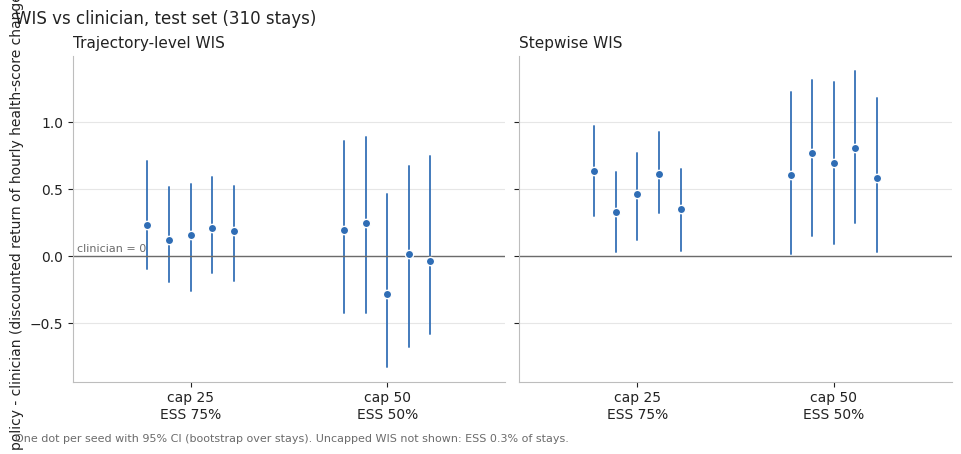

In [12]:
wis.plot_wis_summary(res_by_cap_test, title="WIS vs clinician, test set (310 stays)",
                     uncapped=results_test, save_path=os.path.join(wis_dir, "wis_test_summary.png"));

In [13]:
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
sweep = wis.run_weight_truncation_sweep_for_models(cql_models, bc_models, store, caps, split="test", n_bootstrap=300)

gamma = 0.975 (CQL models' saved discount)
CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=0.589 (traj ESS 98.7%)  step=0.725 (step ESS 98.9%)
  wcap=  5.0  traj=0.712 (traj ESS 94.8%)  step=0.791 (step ESS 94.9%)
  wcap= 10.0  traj=0.738 (traj ESS 90.0%)  step=0.948 (step ESS 90.2%)
  wcap= 25.0  traj=0.874 (traj ESS 74.8%)  step=1.315 (step ESS 75.6%)
  wcap= 50.0  traj=0.835 (traj ESS 50.0%)  step=1.282 (step ESS 51.3%)
  wcap= 75.0  traj=0.472 (traj ESS 25.2%)  step=1.150 (step ESS 26.5%)
  wcap= 90.0  traj=-0.317 (traj ESS 10.3%)  step=0.860 (step ESS 11.7%)
  wcap= 95.0  traj=-1.685 (traj ESS 6.1%)  step=1.310 (step ESS 6.6%)
  wcap= 99.0  traj=-5.802 (traj ESS 1.4%)  step=0.438 (step ESS 1.7%)
CQL seeds loaded: [1]
BC seeds loaded:  [1]
Matched 1 (CQL, BC) pairs by results.json seed: [1]

=== Seed 1: building trajectories once, then sweeping 

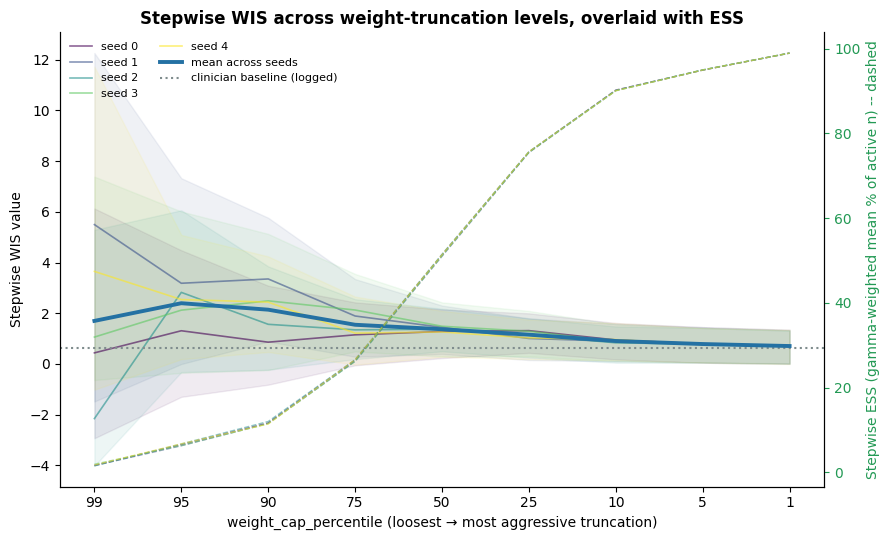

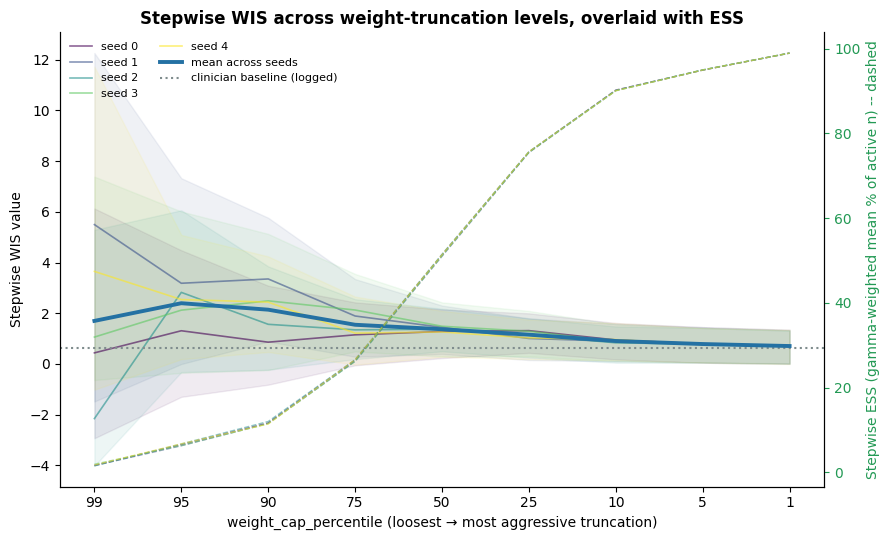

In [14]:
wis.plot_weight_truncation_sweep(sweep, estimator="stepwise")